# Lecture 5: Quantum Dynamics, Observables, and Measurement

[Course contents](../00_course_contents.md) | [← Previous lecture](./04_hilbert_space_and_quantum_mechanics.ipynb) | [Next lecture →](./06_density_matrices_and_entanglement.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** You may download, teach, adapt, and share this notebook with attribution. It can serve a course at any institution, independent study, exam review, or preparation for work in quantum technology. See the [reuse terms](../LICENSE), the [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and the [citation metadata](../CITATION.cff).

## Learning objectives

- Use spectral decompositions to connect Hermitian observables with possible outcomes.
- Apply projective and generalized measurement rules to probabilities and conditional states.
- Compute expectation values, variances, commutators, and uncertainty bounds.
- Construct unitary evolution from a Hamiltonian and distinguish stationary states from superpositions.

## Core ideas

- The spectral projectors of an observable define its outcomes and their probabilities, so an observable carries more structure than a table of matrix entries.
- A measurement model has to specify both the statistics and the state update, because the POVM elements alone do not determine the conditional state.
- The Hamiltonian generates time evolution.
- Noncommuting observables and finite sampling produce two different kinds of uncertainty.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from IPython.core.interactiveshell import InteractiveShell
from sympy.physics.quantum import *
from sympy.physics.quantum.qubit import Qubit
from sympy.physics.quantum.dagger import Dagger
from sympy.physics.quantum.qapply import qapply
from sympy.physics.quantum.represent import represent
from sympy.physics.quantum import pauli
import math
import numpy as np
import matplotlib.pyplot as plt
import sympy as sy
import scipy as sp

In [2]:
%matplotlib inline

In [3]:
InteractiveShell.ast_node_interactivity = "all"

## Observables and spectral decompositions

A finite-dimensional observable is represented by a Hermitian operator $A=A^\dagger$. The spectral theorem gives

$$A=\sum_a aP_a,$$

where the eigenvalues $a\in\mathbb R$, the $P_a$ are mutually orthogonal projectors, and

$$P_aP_b=\delta_{ab}P_a,\qquad \sum_aP_a=I.$$

The outcomes are eigenvalues, not eigenvectors. A degenerate eigenvalue corresponds to a multidimensional eigenspace, so its measurement projector can have rank greater than one.


Position, momentum, and energy become operators after a Hilbert space and appropriate domains are specified. In a finite-dimensional quantum computer, Hermitian matrices are bounded. In continuous-variable mechanics, position and momentum are unbounded operators and their domains matter.

An eigenbasis is a convenient representation when complete, but no coordinate basis is physically privileged. A unitary basis change alters matrix and vector coordinates while preserving probabilities and expectation values.


> **Example: a qubit Hamiltonian in its energy basis**
>
> 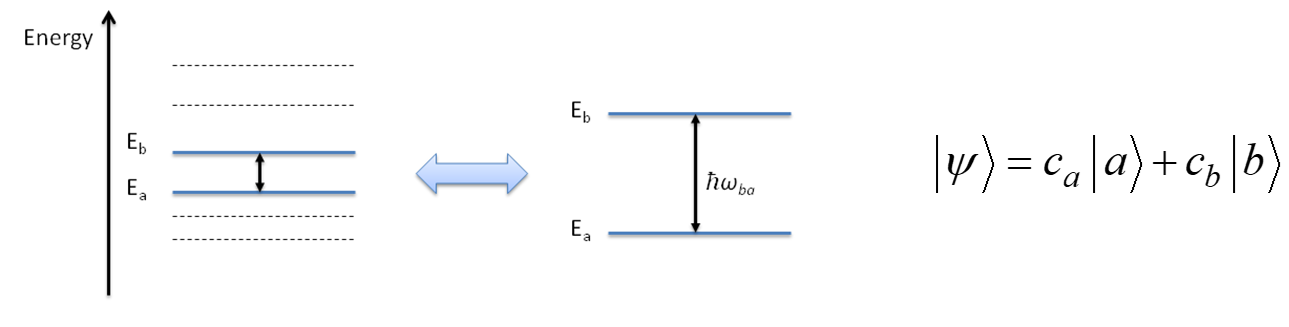
>
> If $\lvert E_a\rangle,\lvert E_b\rangle$ are energy eigenstates, then
>
> $$H=E_a\lvert E_a\rangle\langle E_a\rvert+E_b\lvert E_b\rangle\langle E_b\rvert
> =\begin{bmatrix}E_a&0\\0&E_b\end{bmatrix}.$$
>
> Adding $cI$ shifts both energies and contributes only a global phase to closed-system evolution; it does not change isolated-state measurement probabilities.


### Coordinate representation and a free particle

A plane wave is a generalized momentum eigenstate,

$$\Psi(\mathbf r)=A e^{i\mathbf k\cdot\mathbf r},\qquad \mathbf p=\hbar\mathbf k.$$

On all of space, it is delta-normalized rather than square-normalizable. Physical free-particle states are normalizable wave packets; a constant $A$ normalizes a plane wave only after a finite-box convention is imposed. Here $\lvert\mathbf k\rvert=2\pi/\lambda$ and $\hbar=h/(2\pi)$.

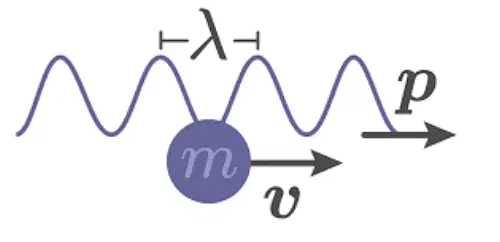


In the coordinate representation,

$$\hat{\mathbf r}\Psi(\mathbf r)=\mathbf r\Psi(\mathbf r),\qquad
\hat{\mathbf p}\Psi(\mathbf r)=-i\hbar\nabla\Psi(\mathbf r).$$

Thus the plane wave above has momentum eigenvalue $\hbar\mathbf k$. For a free particle,

$$H=\frac{\hat{\mathbf p}^{\,2}}{2m}
=-\frac{\hbar^2}{2m}\nabla^2,$$

where $\nabla^2=\partial_x^2+\partial_y^2+\partial_z^2$. In unbounded free space, the position and momentum spectra are continuous and the free-particle energy spectrum is $E\in[0,\infty)$.


For a particle subject to a real scalar potential $V(\mathbf r,t)$,

$$\boxed{H(t)=-\frac{\hbar^2}{2m}\nabla^2+V(\mathbf r,t)}.$$

A time-dependent real potential still gives a Hermitian Hamiltonian under appropriate boundary conditions, but it generally requires a time-ordered propagator.


## Projective measurement

For a normalized pure state $\lvert\psi\rangle$ and the projectors $\{P_a\}$ from an observable's spectral decomposition, the Born probability of outcome $a$ is

$$p(a)=\langle\psi\rvert P_a\lvert\psi\rangle.$$

This includes degenerate outcomes. The word *collapse* is shorthand for conditioning the state on a recorded result; the operational probabilities and update rule do not depend on choosing an interpretation of quantum mechanics.


When $p(a)>0$, the ideal repeatable projective update (Lüders rule) is

$$\lvert\psi_a'\rangle=\frac{P_a\lvert\psi\rangle}{\sqrt{p(a)}}.$$

For $P_a=\lvert a\rangle\langle a\rvert$, this reduces to $p(a)=\lvert\langle a\vert\psi\rangle\rvert^2$. If the classical result is discarded, a nonselective measurement maps

$$\rho\longmapsto \sum_aP_a\rho P_a,$$

which removes coherence between distinct outcome subspaces.


> **Example: projector onto a qubit state**
>
> For $\lvert\phi\rangle=\frac{1}{\sqrt5}[1,2]^T$,
>
> $$P_\phi=\lvert\phi\rangle\langle\phi\rvert
> =\frac15\begin{bmatrix}1&2\\2&4\end{bmatrix}.$$
>
> It is Hermitian and idempotent: $P_\phi^\dagger=P_\phi$ and $P_\phi^2=P_\phi$. Measuring $\{P_\phi,I-P_\phi\}$ on $\lvert0\rangle$ gives $p(\phi)=1/5$.


## General measurements: POVMs and instruments

A positive-operator-valued measure (POVM) is a collection of effects $E_m\succeq0$ satisfying

$$\sum_mE_m=I,\qquad p(m)=\operatorname{Tr}(\rho E_m).$$

Effects determine outcome probabilities but not the post-measurement state. A quantum instrument supplies operators $M_{m\alpha}$:

$$E_m=\sum_\alpha M_{m\alpha}^\dagger M_{m\alpha},\qquad
\rho_m'=\frac{\sum_\alpha M_{m\alpha}\rho M_{m\alpha}^\dagger}{p(m)}.$$

Projective measurement is the special case $M_m=P_m$. POVMs are central to readout engineering and state discrimination because their effects may be nonorthogonal and their number need not equal the Hilbert-space dimension.

**Readout example.** Symmetric assignment error $\epsilon$ can be represented by

$$E_0=(1-\epsilon)\lvert0\rangle\langle0\rvert+\epsilon\lvert1\rangle\langle1\rvert,\qquad
E_1=\epsilon\lvert0\rangle\langle0\rvert+(1-\epsilon)\lvert1\rangle\langle1\rvert.$$

Calibration-matrix inversion can reduce bias, but amplifies statistical uncertainty if the matrix is ill-conditioned.


## Expectation values and variance

For a normalized pure state,

$$\boxed{\langle A\rangle=\langle\psi\rvert A\lvert\psi\rangle},$$

and for a density operator, $\langle A\rangle=\operatorname{Tr}(\rho A)$. An expectation value is an ensemble mean, not generally a possible single-shot outcome. Define

$$\operatorname{Var}(A)=\langle A^2\rangle-\langle A\rangle^2,\qquad
\Delta A=\sqrt{\operatorname{Var}(A)}.$$


If $\lvert\psi\rangle=\sum_n c_n\lvert n\rangle$, then

$$\langle A\rangle=\sum_{n,m}c_n^*c_m\langle n\rvert A\lvert m\rangle.$$

If $\lvert\psi\rangle$ lies in an eigenspace of $A$ with eigenvalue $a$, every ideal measurement returns $a$, so $\Delta A=0$. Conversely, $\Delta A=0$ means the state has support in one eigenspace; degeneracy need not select one eigenvector.


> **Example: expectation and variance**
>
> Let
>
> $$H=\begin{bmatrix}2&1-i\\1+i&3\end{bmatrix},\qquad
> \lvert\psi\rangle=\frac1{\sqrt2}\begin{bmatrix}1\\i\end{bmatrix}.$$
>
> Then
>
> $$\langle H\rangle=\frac72,\qquad
> \langle H^2\rangle=\frac{27}{2},\qquad
> \operatorname{Var}(H)=\frac54.$$
>
> The mean is real because $H$ is Hermitian, but it is not required to equal an eigenvalue.


In [4]:
psi_np = np.array([1, 1j], dtype=complex) / np.sqrt(2)
H_np = np.array([[2, 1 - 1j], [1 + 1j, 3]], dtype=complex)

mean_H = np.vdot(psi_np, H_np @ psi_np)
mean_H2 = np.vdot(psi_np, H_np @ H_np @ psi_np)
variance_H = mean_H2 - mean_H**2
np.real_if_close([mean_H, mean_H2, variance_H])

array([ 3.5 , 13.5 ,  1.25])

## Compatibility, commutators, and uncertainty


Two finite-dimensional observables admit a common sharp projective measurement exactly when their spectral projectors commute; for Hermitian $A,B$, this is equivalent to

$$[A,B]=AB-BA=0.$$

This does not mean that arbitrary laboratory procedures for $A$ and $B$ are nondisturbing, nor that generalized approximate joint measurements are impossible when $[A,B]\ne0$.

For position and momentum, applying the product rule to a suitable wavefunction gives

$$[x,p_x]\psi=x(-i\hbar\partial_x\psi)+i\hbar\partial_x(x\psi)=i\hbar\psi,$$

so $[x,p_x]=i\hbar I$.


### Robertson uncertainty relation

For Hermitian $A,B$, define $\widetilde A=A-\langle A\rangle I$ and $\widetilde B=B-\langle B\rangle I$. Cauchy–Schwarz yields

$$\boxed{\Delta A\,\Delta B\ge\frac12\left|\langle[A,B]\rangle\right|}.$$

The stronger Robertson–Schrödinger relation includes covariance:

$$\Delta A^2\Delta B^2\ge
\frac14\left|\langle[A,B]\rangle\right|^2+
\frac14\left|\langle\{\widetilde A,\widetilde B\}\rangle\right|^2.$$

For $\lvert0\rangle$, $\Delta X=\Delta Y=1$ and $\langle[X,Y]\rangle=2i$, so the Robertson bound is saturated. For position and momentum it gives $\Delta x\Delta p_x\ge\hbar/2$. This concerns distributions over identically prepared systems, not only instrumental precision.

Primary reference: H. P. Robertson, [“The Uncertainty Principle,” Physical Review 34, 163 (1929)](https://doi.org/10.1103/PhysRev.34.163).


In [5]:
Qubit(0)
Dagger(Qubit(0))

|0>

<0|

In [6]:
phi, psi = Ket('phi'), Ket('psi')

phi
psi

|phi>

|psi>

SymPy represents symbolic noncommuting operators and their adjoints.


In [7]:
A = Operator('A')
B = Operator('B')
H = HermitianOperator('H')

type(A)
type(H)

sympy.physics.quantum.operator.Operator

sympy.physics.quantum.operator.HermitianOperator

Operator multiplication is noncommutative unless assumptions or simplification rules say otherwise. Thus expanding $(A+B)^2$ retains both $AB$ and $BA$.


In [8]:
((A+B)**2).expand()

sy.expand((A+B)**2)

A*B + A**2 + B*A + B**2

A*B + A**2 + B*A + B**2

Commutators can be represented symbolically:


In [9]:
Commutator(H,A)

[H,A]

In [10]:
C = Operator('C')
comm = Commutator(A * B, B + C)
comm

[A*B,B + C]

In [11]:
comm.expand(commutator=True)

[A,B]*B + [A,C]*B + A*[B,C]

The doit method expands a commutator according to $[A,B]=AB-BA$. This is formal operator algebra; it does not assign a matrix representation automatically.


In [12]:
expanded_comm = comm.expand(commutator=True)
expanded_comm

[A,B]*B + [A,C]*B + A*[B,C]

In [13]:
evaluated_comm = expanded_comm.doit()
evaluated_comm

(A*B - B*A)*B + (A*C - C*A)*B + A*(B*C - C*B)

In [14]:
evaluated_comm.expand()

A*B*C + A*B**2 - B*A*B - C*A*B

The Dagger operation reverses product order: $(AB)^\dagger=B^\dagger A^\dagger$. For a Hermitian operator $H^\dagger=H$.


In [15]:
Dagger(H), Dagger(A * B)

(H, Dagger(B)*Dagger(A))

## Spin-1/2 observables and Pauli matrices


Spin is intrinsic angular momentum, not the literal rotation of an extended classical object. For a spin-$1/2$ degree of freedom,

$$S_x=\frac{\hbar}{2}X,\qquad S_y=\frac{\hbar}{2}Y,\qquad S_z=\frac{\hbar}{2}Z.$$

The eigenvalues of $S_{\mathbf n}=(\hbar/2)\mathbf n\cdot\boldsymbol\sigma$ are $\pm\hbar/2$; the dimensionless Pauli observable has eigenvalues $\pm1$.


### Stern–Gerlach experiment

A beam of silver atoms in an inhomogeneous magnetic field splits into discrete components rather than a classical continuous distribution. In a simplified two-level description the apparatus measures an angular-momentum component. A historical note: the 1922 experiment predates the modern explanation based on electron spin; the magnetic moment belongs to the atom's unpaired electron.

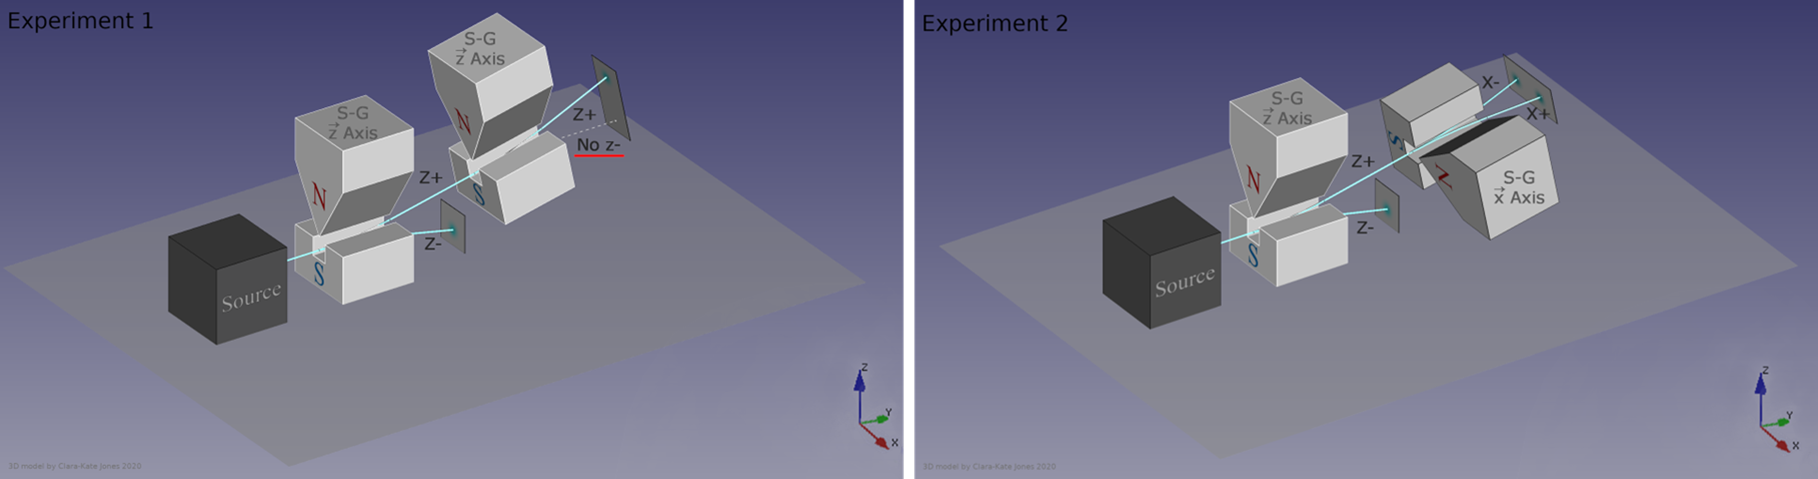

For direction $\mathbf n$, the two projectors are

$$P_\pm=\frac12(I\pm\mathbf n\cdot\boldsymbol\sigma),$$

and a qubit with Bloch vector $\mathbf r$ gives $p(\pm)=(1\pm\mathbf n\cdot\mathbf r)/2$.


### Pauli algebra

$$X=\begin{bmatrix}0&1\\1&0\end{bmatrix},\qquad
Y=\begin{bmatrix}0&-i\\i&0\end{bmatrix},\qquad
Z=\begin{bmatrix}1&0\\0&-1\end{bmatrix}.$$

They satisfy

$$\sigma_i\sigma_j=\delta_{ij}I+i\sum_k\epsilon_{ijk}\sigma_k,$$

$$[\sigma_i,\sigma_j]=2i\sum_k\epsilon_{ijk}\sigma_k,\qquad
\{\sigma_i,\sigma_j\}=2\delta_{ij}I.$$

Each Pauli matrix is Hermitian, unitary, traceless, and squares to $I$. Pauli strings form an orthogonal operator basis under the Hilbert–Schmidt inner product.


In [16]:
PX = pauli.SigmaX()
PY = pauli.SigmaY()
PZ = pauli.SigmaZ()
PX, PY, PZ

(SigmaX(), SigmaY(), SigmaZ())

In [17]:
represent(PX)
represent(PY)
represent(PZ)

Matrix([
[0, 1],
[1, 0]])

Matrix([
[0, -I],
[I,  0]])

Matrix([
[1,  0],
[0, -1]])

In [18]:
# Unitary: sigma_i sigma_i^\dagger = I
PX * Dagger(PX)
PY * Dagger(PY)
PZ * Dagger(PZ)

1

1

1

In [19]:
# Hermitian: sigma_i^\dagger = sigma_i
Dagger(PX)
Dagger(PY)
Dagger(PZ)

SigmaX()

SigmaY()

SigmaZ()

In [20]:
Commutator(PX,PY).doit()
Commutator(PY,PZ).doit()

2*I*SigmaZ()

2*I*SigmaX()

## Eigenstates and eigenvalues of Pauli observables


| Observable | $+1$ eigenstate | $-1$ eigenstate |
|---|---|---|
| $X$ | $\frac1{\sqrt2}[1,1]^T=\lvert+\rangle$ | $\frac1{\sqrt2}[1,-1]^T=\lvert-\rangle$ |
| $Y$ | $\frac1{\sqrt2}[1,i]^T=\lvert+i\rangle$ | $\frac1{\sqrt2}[1,-i]^T=\lvert-i\rangle$ |
| $Z$ | $[1,0]^T=\lvert0\rangle$ | $[0,1]^T=\lvert1\rangle$ |

For physical spin $S_i=(\hbar/2)\sigma_i$, multiply the tabulated eigenvalues by $\hbar/2$.


In [21]:
represent(Qubit(0))
represent(Qubit(1))

Matrix([
[1],
[0]])

Matrix([
[0],
[1]])

## Closed-system time evolution

The Schrödinger equation is

$$i\hbar\frac{d}{dt}\lvert\psi(t)\rangle=H(t)\lvert\psi(t)\rangle.$$

For a time-independent Hamiltonian,

$$\lvert\psi(t)\rangle=U(t)\lvert\psi(0)\rangle,\qquad
U(t)=e^{-iHt/\hbar},\qquad U^\dagger U=I.$$

For a time-dependent Hamiltonian whose values do not commute at different times,

$$U(t,t_0)=\mathcal T\exp\left[-\frac{i}{\hbar}\int_{t_0}^{t}H(s)\,ds\right].$$

The density-operator equation is $\dot\rho=-(i/\hbar)[H,\rho]$. Calling $T+V$ conserved energy is valid only when the Hamiltonian has no explicit time dependence.


### Driven qubit: Hamiltonians become gates

An engineered drive is often modeled in a rotating frame by

$$H=\frac{\hbar}{2}(\Omega_xX+\Omega_yY+\Delta Z)
=\frac{\hbar\Omega}{2}\mathbf n\cdot\boldsymbol\sigma,$$

where $\Omega=\sqrt{\Omega_x^2+\Omega_y^2+\Delta^2}$. For a constant pulse of duration $t$,

$$U(t)=\cos\frac{\Omega t}{2}I-i\sin\frac{\Omega t}{2}\mathbf n\cdot\boldsymbol\sigma
=R_{\mathbf n}(\Omega t).$$

The pulse area sets the rotation angle, the drive phase selects an equatorial axis, and the detuning adds a $Z$ component. An error in calibrating any of these Hamiltonian parameters therefore appears directly as a coherent gate error.

See MIT OpenCourseWare, [Quantum Theory I, Lecture 8](https://ocw.mit.edu/courses/8-321-quantum-theory-i-fall-2017/resources/mit8_321f17_lec8/).


### Stationary states and superpositions

If $H\lvert E_n\rangle=E_n\lvert E_n\rangle$, then

$$\lvert E_n(t)\rangle=e^{-iE_nt/\hbar}\lvert E_n\rangle.$$

Its probability density is time independent, so it is a stationary state. A general state under the same time-independent Hamiltonian is

$$\lvert\psi(t)\rangle=\sum_n c_ne^{-iE_nt/\hbar}\lvert E_n\rangle.$$

Relative phases $e^{-i(E_n-E_m)t/\hbar}$ can make observable statistics time dependent even though every component is an energy eigenstate. The relation $E=\hbar\omega$ connects one energy eigenvalue to its phase angular frequency; observable beat frequencies depend on energy differences.


### Particle in an infinite square well

$$V(x)=\begin{cases}
0,&0<x<a,\\
\infty,&\text{otherwise}.
\end{cases}$$

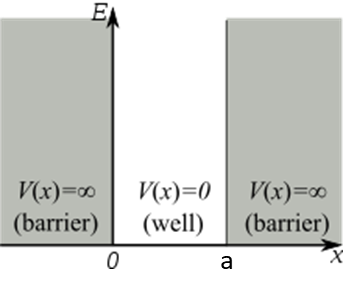


Inside the well,

$$-\frac{\hbar^2}{2m}\frac{d^2\phi}{dx^2}=E\phi,$$

with boundary conditions $\phi(0)=\phi(a)=0$. The normalized eigenfunctions and energies are

$$\boxed{\phi_n(x)=\sqrt{\frac2a}\sin\frac{n\pi x}{a}},\qquad
\boxed{E_n=\frac{\hbar^2\pi^2n^2}{2ma^2}},\quad n=1,2,\ldots$$

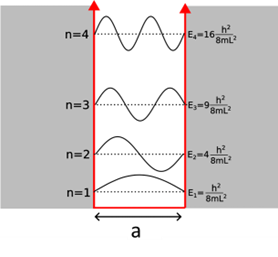

The boundary conditions select $k_n=n\pi/a$. A superposition of these eigenstates stays normalized, but its probability density need not be stationary.


## Finite-shot estimation

For a binary outcome with probability $p$, the number $K$ of ones in $N$ independent shots is binomial:

$$K\sim\operatorname{Binomial}(N,p),\qquad
\operatorname{Var}(K/N)=\frac{p(1-p)}{N}.$$

The worst-case standard error of a probability estimate is $1/(2\sqrt N)$. Reducing it by a factor of ten requires one hundred times as many shots. This uncertainty exists even for a perfect device and must be distinguished from systematic state-preparation, gate, and readout errors.

For a Pauli outcome $X\in\{-1,+1\}$,

$$\operatorname{SE}(\bar X)=\sqrt{\frac{1-\langle X\rangle^2}{N}}.$$

Engineering reports should state shot count, estimator, and uncertainty method instead of treating a histogram as an exact distribution.


## Key takeaways

- Spectral projectors connect Hermitian observables to outcome probabilities and post-measurement states.
- POVMs describe generalized measurement statistics; instruments additionally specify conditional evolution.
- Commutators control compatibility and Robertson uncertainty, while shot noise is a statistical estimation effect.
- Closed-system dynamics is unitary, $U(t)=e^{-iHt/\hbar}$, and superpositions of energy eigenstates acquire relative phase.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. J. J. Sakurai and J. Napolitano, *Modern Quantum Mechanics*, 3rd ed. (Cambridge University Press, 2020).
2. M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information* (Cambridge University Press, 2010), Sections 2.2 and 8.2.
3. J. Preskill, [Quantum Information, Chapter 2](https://www.preskill.caltech.edu/ph219/chap2_15.pdf).
4. H. P. Robertson, [“The Uncertainty Principle,” Physical Review 34, 163–164 (1929)](https://doi.org/10.1103/PhysRev.34.163).
5. MIT OpenCourseWare, [Quantum Theory I, Lecture 8](https://ocw.mit.edu/courses/8-321-quantum-theory-i-fall-2017/resources/mit8_321f17_lec8/).
6. IBM Quantum, [Operators overview](https://quantum.cloud.ibm.com/docs/en/guides/operators-overview).
